
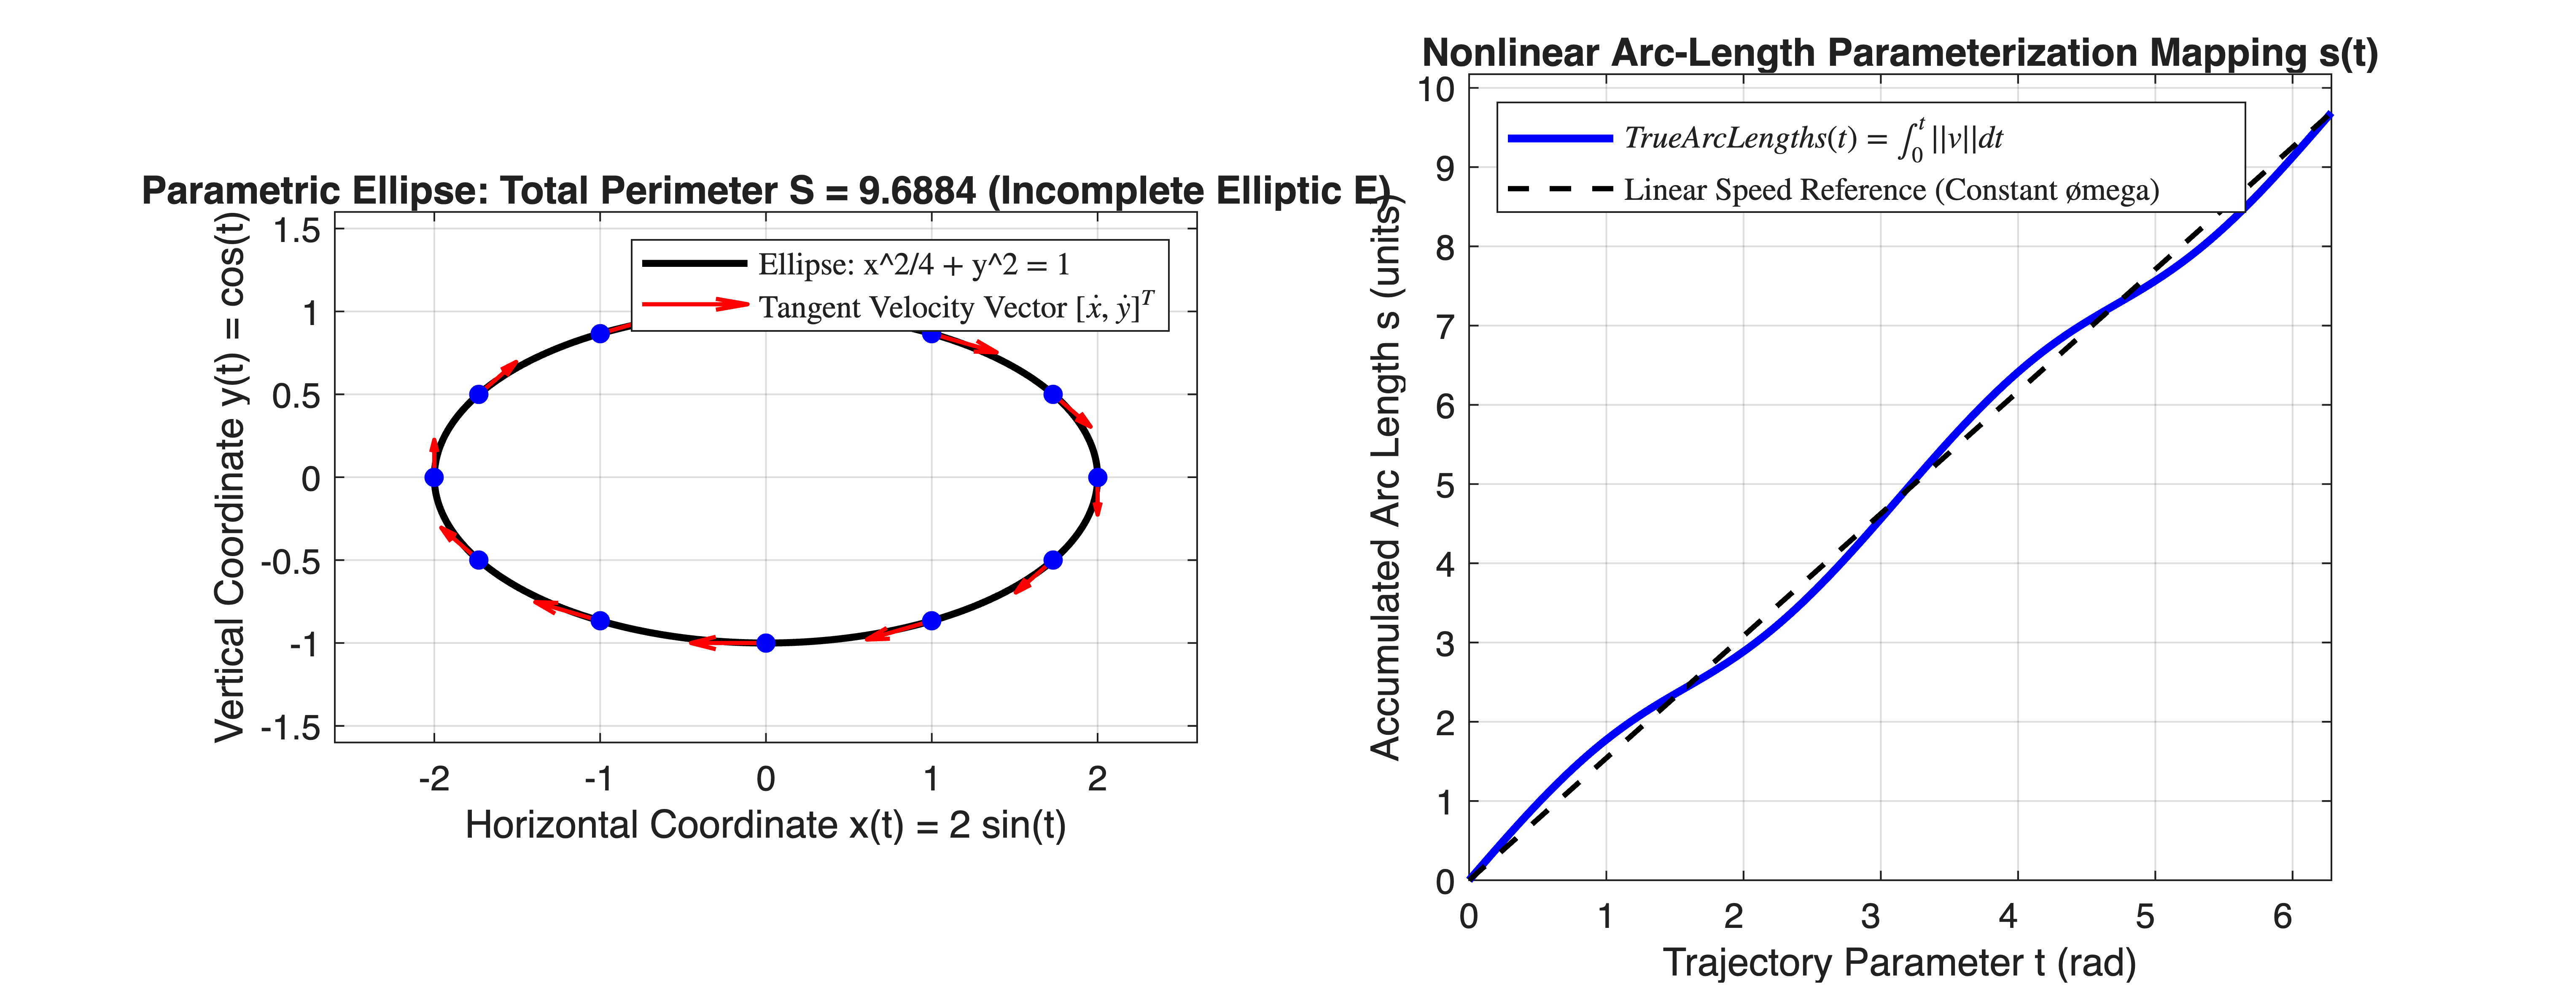

In [1]:
%% MIT 18.01 Lecture 30: Integration by Parts, Recurrence & Arc Length Simulation
% Mathematical Tool Application: Used for costate integration in optimal control,
% arc-length parameterization for autonomous vehicle path tracking (Frenet frame),
% and higher-order moments evaluation via reduction formulas.


clear; clc; close all;


%% Part 1: Parametric Ellipse Kinematics & Arc Length Accumulation (Example 7)
% Ellipse Parametric Equations: x(t) = 2*sin(t), y(t) = cos(t)
% Tangent Velocities: dx/dt = 2*cos(t), dy/dt = -sin(t)
% Arc Length Speed: ds/dt = sqrt((2*cos(t))^2 + (-sin(t))^2) = sqrt(4*cos^2(t) + sin^2(t))
%                         = sqrt(1 + 3*cos^2(t))
t_span = linspace(0, 2*pi, 400);
x_ellipse = 2.0 * sin(t_span);
y_ellipse = cos(t_span);


speed_profile = sqrt(4.0 * (cos(t_span).^2) + (sin(t_span).^2));


% Cumulative arc length s(t) via numerical trapezoidal integration
s_accumulated = cumtrapz(t_span, speed_profile);
total_perimeter = s_accumulated(end);


figure('Color', 'w', 'Position', [100, 100, 1250, 480]);


subplot(1, 2, 1);
plot(x_ellipse, y_ellipse, 'k-', 'LineWidth', 2.0, 'DisplayName', 'Ellipse: x^2/4 + y^2 = 1'); hold on;


% Plot tangent velocity arrows at selected intervals
t_arrows = linspace(0, 2*pi - pi/6, 12);
x_arr = 2.0 * sin(t_arrows);
y_arr = cos(t_arrows);
dx_arr = 2.0 * cos(t_arrows);
dy_arr = -sin(t_arrows);
quiver(x_arr, y_arr, dx_arr, dy_arr, 0.35, 'r', 'LineWidth', 1.2, ...
    'DisplayName', 'Tangent Velocity Vector $[\dot{x}, \dot{y}]^T$');


plot(x_arr, y_arr, 'bo', 'MarkerSize', 5, 'MarkerFaceColor', 'b', 'HandleVisibility', 'off');
grid on; axis equal;
xlim([-2.6, 2.6]); ylim([-1.6, 1.6]);
xlabel('Horizontal Coordinate x(t) = 2 sin(t)');
ylabel('Vertical Coordinate y(t) = cos(t)');
title(sprintf('Parametric Ellipse: Total Perimeter S = %.4f (Incomplete Elliptic E)', total_perimeter));
legend('Location', 'northeast', 'Interpreter', 'latex');


%% Subplot 2: Parameter t vs. True Accumulated Arc Length s(t)
subplot(1, 2, 2);
plot(t_span, s_accumulated, 'b-', 'LineWidth', 2.2, 'DisplayName', '$True Arc Length s(t) = \int_0^t ||v|| dt$'); hold on;
plot(t_span, (total_perimeter / (2*pi)) * t_span, 'k--', 'LineWidth', 1.5, ...
    'DisplayName', 'Linear Speed Reference (Constant \omega)');


grid on;
xlim([0, 2*pi]); ylim([0, total_perimeter * 1.05]);
xlabel('Trajectory Parameter t (rad)');
ylabel('Accumulated Arc Length s (units)');
title('Nonlinear Arc-Length Parameterization Mapping s(t)');
legend('Location', 'northwest', 'Interpreter','latex');

In [2]:


%% Part 2: Reduction Formula Verification: I_n = \int_0^T x^n * exp(-x) dx (Example 4)
% Recurrence: I_n = -T^n * exp(-T) + n * I_{n-1},  Base: I_0 = 1 - exp(-T)
T_upper = 2.5;
max_order_n = 5;


I_recurrence = zeros(max_order_n + 1, 1);
I_numerical  = zeros(max_order_n + 1, 1);


% Base case n = 0
I_recurrence(1) = 1.0 - exp(-T_upper);
I_numerical(1)  = integral(@(x) exp(-x), 0, T_upper);


% March forward using reduction formula
for n = 1:max_order_n
    I_recurrence(n+1) = -(T_upper^n) * exp(-T_upper) + n * I_recurrence(n);
    I_numerical(n+1)  = integral(@(x) (x.^n) .* exp(-x), 0, T_upper, 'RelTol', 1e-12, 'AbsTol', 1e-14);
end


fprintf('\n=== Lecture 30 Reduction Formula: I_n = \\int_0^{%.1f} x^n e^{-x} dx ===\n', T_upper);

=== Lecture 30 Reduction Formula: I_n = \int_0^{2.5} x^n e^{-x} dx ===

In [3]:
for n = 0:max_order_n
    fprintf('  Order n = %d: Recurrence = %12.8f | Numerical = %12.8f | Residual = %.2e\n', ...
        n, I_recurrence(n+1), I_numerical(n+1), abs(I_recurrence(n+1) - I_numerical(n+1)));
end

  Order n = 0: Recurrence =   0.91791500 | Numerical =   0.91791500 | Residual = 0.00e+00
  Order n = 1: Recurrence =   0.71270250 | Numerical =   0.71270250 | Residual = 0.00e+00
  Order n = 2: Recurrence =   0.91237377 | Numerical =   0.91237377 | Residual = 0.00e+00
  Order n = 3: Recurrence =   1.45454320 | Numerical =   1.45454320 | Residual = 4.44e-16
  Order n = 4: Recurrence =   2.61172755 | Numerical =   2.61172755 | Residual = 1.33e-15
  Order n = 5: Recurrence =   5.04252458 | Numerical =   5.04252458 | Residual = 5.33e-15